# Проверка TabPFN-3.5 на данных о сценариях потребления энергии (SmartPlug)

**Проблема:** новейшая табличная foundation-модель **TabPFN-3.5** заявляет SOTA-результаты в задачах классификации и регрессии на сырых табличных данных, в том числе без масштабирования и подбора гиперпараметров. Нужно проверить, как она работает на наших данных — фрагментах кривой мощности из дампов SmartPlug (сценарии использования электроприборов), — и заодно ответить на два практических вопроса:

1. **Требуется ли GPU, или можно запустить на CPU?**
2. **Если нужен GPU — поместится ли модель в T4, доступную бесплатно в Google Colab?**

**Источники:**

- Технический отчёт: https://arxiv.org/abs/2609.17895
- Обзор отчёта: https://arxiviq.substack.com/p/tabpfn-35-technical-report
- Код (pip-пакет `tabpfn`): https://github.com/PriorLabs/TabPFN
- Веса модели: https://huggingface.co/Prior-Labs/tabpfn_3_5

**Данные:** дампы SmartPlug в Google Drive (`/content/drive/MyDrive/SmartPlug`), файлы вида
`plug_dump_<время>_<метка>_<длительность>.csv`, кривые мощности режутся на фрагменты по 90 точек —
тот же формат, что и в референс-ноутбуке `TimesFM3_DeepSeek.ipynb`.

**Лицензия:** веса TabPFN-3.5 распространяются по некоммерческой лицензии: тестирование
и внутренняя оценка разрешены, коммерческое использование — нет.

**Как пользоваться:** `Runtime → «Запустить всё» (Run All)`. Подойдут
и T4-GPU, и CPU-рантайм — блок 3 сам определит окружение. При первом `fit` модель скачает
чекпоинт с Hugging Face, это займет пару минут.


## 1. Установка зависимостей

Минимизируем зависимости: всё, кроме `tabpfn`, в Colab уже предустановлено
(`torch`, `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `tqdm`).
Ставим единственный недостающий пакет — официальный PyPI-пакет Prior Labs с кодом для работы с моделью; он же скачает веса при первом `fit`.

In [10]:
# ЧТО ДЕЛАЕМ: ставим единственный недостающий пакет — `tabpfn`.
# ЗАЧЕМ: именно в нём лежат TabPFNClassifier/TabPFNRegressor и логика загрузки чекпоинта
# c Hugging Face. Всё остальное уже есть в Colab, поэтому других установок в ноутбуке нет
# (требование минимизации зависимостей).
%pip install -q tabpfn

## 2. Импорты и параметры окружения

Все импорты собираем в одной ячейке, чтобы сразу видеть отсутствие "лишних" пакетов:
каждый импорт пригодится в следующих блоках.

In [11]:
# ЧТО ДЕЛАЕМ: импортируем всё необходимое и фиксируем зерна генераторов случайных чисел.
# ЗАЧЕМ: единая ячейка импортов упрощает проверку "нет лишнего"; фиксированное зерно
# делает разбиение train/test воспроизводимым от запуска к запуску (как в референс-ноутбуке).
import os    # обход папки Google Drive со дампами SmartPlug
import re    # извлечение метки и длительности из имён файлов plug_dump_*.csv
import time  # замеры длительности fit/predict для сравнения вариантов модели

import numpy as np                  # матрица фрагментов и подсчет распределения меток
import pandas as pd                 # чтение CSV-дампов с разделителем ';', сводная таблица результатов
import torch                        # проверка наличия GPU (CUDA) в Colab-рантайме
import matplotlib.pyplot as plt     # отрисовка матрицы ошибок
from tqdm import tqdm               # прогресс-бар по файлам дампа

from google.colab import drive  # подключение Google Drive, откуда читаются данные
from sklearn.model_selection import train_test_split      # стратифицированное разбиение выборки
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay  # метрики классификации

from tabpfn import TabPFNClassifier        # интерфейс модели TabPFN (обучение в контексте, zero-shot)
from tabpfn.constants import ModelVersion  # выбор версии чекпоинта: V3_5 (base) и V3_5_FAST

np.random.seed(42)      # зерно для numpy (как в референс-ноутбуке)
torch.manual_seed(42)   # зерно для torch (как в референс-ноутбуке)

## 3. Проверка окружения: GPU или CPU?

Официальные характеристики из README репозитория и карточки модели ([arXiv 2609.17895](https://arxiv.org/abs/2609.17895), [Hugging Face](https://huggingface.co/Prior-Labs/tabpfn_3_5)):

- **GPU рекомендуется**, но не обязателен: ~8 ГБ VRAM хватает; 16 ГБ нужны только для очень больших датасетов;
- **на CPU** возможны умеренные датасеты — лимит примерно **5000 строк** (TabPFN-3 / TabPFN-3.5 / TabPFN-3.5-Fast);
- предельные размеры: до **1 000 000 строк** и **20 000 признаков** (на GPU);
- **предобработка не нужна**: не масштабируем и не делаем one-hot; большой test-набор предсказываем батчами ≤ 1000 строк;
- TabPFN-3.5 — трансформер примерно на **220 млн параметров**, весовой файл ≈0,9 ГБ — скачается при первом `fit`.

Смелые заявления из документации проверим фактически: ячейка ниже печатает версию PyTorch,
наличие CUDA, имя GPU и его VRAM. У Colab-T4 это "Tesla T4" и 16 ГБ.

In [12]:
# ЧТО ДЕЛАЕМ: определяем фактическое окружение и печатаем короткий отчет.
# ЗАЧЕМ: ответить на вопросы "GPU обязателен?" и "уместится ли в T4?" не по документации,
# а по тому, что реально досталось рантайму; DEVICE дальше понадобится CPU-эвристике из раздела 4.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch: {torch.__version__}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1024**3
    print(f"GPU найден: {props.name}, VRAM ~{vram_gb:.1f} ГБ")
    print("Ответ на вопрос 1: GPU есть — TabPFN-3.5 будет работать быстро и без CPU-лимита ~5000 строк.")
    print("Ответ на вопрос 2: 220 млн параметров (веса ~0,9 ГБ) легко помещаются и в 8, и в 16 ГБ VRAM —")
    print("если это T4 (16 ГБ из Colab), запас очень большой.")
else:
    print("CUDA недоступна — работаем на CPU.")
    print("Ответ на вопрос 1: GPU не обязателен: наш датасет (фрагменты по 90 точек, несколько тысяч строк)")
    print("укладывается в CPU-лимит ~5000 строк; будет медленнее, но полностью рабочий.")
    print("Ответ на вопрос 2: T4 не задействована — если захочется скорости, включите T4-рантайм в Colab.")

PyTorch: 2.11.0+cu130
GPU найден: Tesla T4, VRAM ~14.6 ГБ
Ответ на вопрос 1: GPU есть — TabPFN-3.5 будет работать быстро и без CPU-лимита ~5000 строк.
Ответ на вопрос 2: 220 млн параметров (веса ~0,9 ГБ) легко помещаются и в 8, и в 16 ГБ VRAM —
если это T4 (16 ГБ из Colab), запас очень большой.


## 4. Загрузка и подготовка данных

Формат данных полностью повторяет референс-ноутбук `TimesFM3_DeepSeek.ipynb`:

- папка `/content/drive/MyDrive/SmartPlug` на Google Drive;
- имена файлов: `plug_dump_<YYYY>_<MM>_<DD>_<HH>_<MM>_<SS>_<метка>_<длительность>.csv`;
- разделитель `;`, нужный столбец — ` P_RMS, mW` (обратите внимание на пробел в начале имени!);
- каждый файл — непрерывная кривая мощности, его режем на последовательные фрагменты по **90 точек**;
- метка сценария берется из имени файла;
- шумовые классы (`IdleCharge`, `Browsing` — включая `MixedBrowsing`, `VKAudio`) исключаем так же, как референс.


In [13]:
# ЧТО ДЕЛАЕМ: подключаем Google Drive и проверяем, что папка SmartPlug с дампами на месте.
# ЗАЧЕМ: без Drive данные не прочитать; явная проверка пути дает понятную ошибку
# вместо малопонятного падения где-то внутри загрузки.

# Подключаем Google Drive (как в референс-ноутбуке)
drive.mount('/content/drive')

SMARTPLUG_DIR = '/content/drive/MyDrive/SmartPlug'  # тот же путь, что в TimesFM3_DeepSeek.ipynb

if not os.path.isdir(SMARTPLUG_DIR):
    raise FileNotFoundError(
        f"Папка {SMARTPLUG_DIR} не найдена. Подключите Google Drive c дампами SmartPlug, "
        f"или поправьте путь SMARTPLUG_DIR, если дампы лежат в другом месте."
    )

files = sorted(f for f in os.listdir(SMARTPLUG_DIR) if os.path.isfile(os.path.join(SMARTPLUG_DIR, f)))
print(f"Найдено файлов в папке: {len(files)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Найдено файлов в папке: 54


In [14]:
# ЧТО ДЕЛАЕМ: описываем функции загрузки дампов в табличную выборку.
# ЗАЧЕМ: кривые мощности из CSV превращаем в классические табличные данные —
# каждая строка это фрагмент из 90 значений мощности, целевая метка — из имени файла.
# Именно raw-таблицу TabPFN и ждет: без TimesFM-признаков и без нашей предобработки.

CHUNK_LENGTH = 90                 # длина одного фрагмента (как в референс-ноутбуке)
POWER_COLUMN = ' P_RMS, mW'       # столбец со среднеквадратичной мощностью (пробел в начале — как в дампах)
# Шумовые метки референс-ноутбука; 'MixedBrowsing' тоже отсеется, т.к. содержит 'Browsing'.
EXCLUDED_LABELS = ('IdleCharge', 'Browsing', 'VKAudio')


def GetLabelDuration(filename: str) -> tuple[str | None, int]:
    """Извлекает (метку, длительность) из имени дамп-файла по шаблону plug_dump_*.

    Возвращает (None, 0), если имя не подходит под шаблон.
    Логика и регулярные выражения повторяют референс-ноутбук TimesFM3_DeepSeek.ipynb.
    """
    try:
        duration = re.findall(r'plug_dump_\d{4}_\d{2}_\d{2}_\d{2}_\d{2}_\d{2}_\D+?_(\d+?).csv', filename)[0]
        label = re.findall(r'plug_dump_\d{4}_\d{2}_\d{2}_\d{2}_\d{2}_\d{2}_(\D+?)_\d+?.csv', filename)[0]
        return label, int(duration)
    except IndexError:
        return None, 0


def load_smartplug_dataset(folder: str, filenames: list[str]) -> tuple[np.ndarray, list[str]]:
    """Собирает датасет из дамп-файлов SmartPlug.

    Для каждого файла:
      1) достает метку из имени (GetLabelDuration), отсеивая шумовые классы;
      2) читает CSV с разделителем ';';
      3) столбец ` P_RMS, mW` режет на последовательные фрагменты по 90 точек;
      4) каждый фрагмент становится строкой будущей матрицы X, его метка попадает в y.

    Файлы с неправильным именем, без нужного столбца или короче 90 точек пропускаются
    с печатным предупреждением, не прерывая загрузку.

    Returns:
        X — np.ndarray формы (N, 90) float32: по строке на фрагмент;
        y — список меток сценариев той же длины, что и X.
    """
    chunks: list[np.ndarray] = []
    labels: list[str] = []
    n_bad_name = n_filtered = n_bad_data = 0

    for filename in tqdm(filenames, desc="Обработка файлов"):
        label, _ = GetLabelDuration(filename)
        if label is None:
            # Имя не подходит под шаблон plug_dump_* — файл не опознан
            print(f"[ПРОПУСК] имя не соответствует шаблону: {filename}")
            n_bad_name += 1
            continue
        if any(bad in label for bad in EXCLUDED_LABELS):
            n_filtered += 1
            continue
        try:
            df = pd.read_csv(os.path.join(folder, filename), delimiter=';')
            series = df[POWER_COLUMN]  # кривая мощности из дампа
        except Exception as e:
            print(f"[ПРОПУСК] {filename}: не удалось прочитать кривую мощности ({e})")
            n_bad_data += 1
            continue
        num_chunks = len(series) // CHUNK_LENGTH
        if num_chunks == 0:
            print(f"[ПРОПУСК] {filename}: меньше, чем {CHUNK_LENGTH} точек мощности")
            n_bad_data += 1
            continue
        # Режем на последовательные фрагменты, ровно как в референс-ноутбуке
        for i in range(num_chunks):
            chunk = series.iloc[i * CHUNK_LENGTH:(i + 1) * CHUNK_LENGTH].to_numpy(dtype=np.float32)
            chunks.append(chunk)
            labels.append(label)

    if not labels:
        raise RuntimeError("Данные не прочитаны: ни один файл не дал фрагментов. Проверьте содержимое дампов.")

    print(f"Файлов: обработано {len(filenames)}; не распознано имен — {n_bad_name}, "
          f"отсеяно по меткам — {n_filtered}, без данных — {n_bad_data}")
    print(f"Всего фрагментов: {len(labels)}")
    return np.stack(chunks), labels

In [15]:
# ЧТО ДЕЛАЕМ: запускаем загрузку и печатаем обзор собранного датасета.
# ЗАЧЕМ: убедиться, что выборка собралась целиком, и посмотреть классы и их частоты;
# строковая форма y (имена классов) идет прямо в TabPFN, кодирование меток не нужно.
# Здесь же CPU-эвристика: если строк много, а GPU нет — предупреждаем про лимит.

X, y = load_smartplug_dataset(SMARTPLUG_DIR, files)
y = np.asarray(y)

print(f"Форма массива данных: {X.shape}")
unique, counts = np.unique(y, return_counts=True)
print("Метки и число фрагментов (по 90 точек в каждом):")
for lab, cnt in zip(unique, counts):
    print(f"  {lab}: {cnt}")

CPU_ROW_LIMIT = 5000  # документированный лимит CPU-профиля TabPFN-3 / 3.5 / 3.5-Fast
if DEVICE.type == "cpu" and X.shape[0] > CPU_ROW_LIMIT:
    print(f"[ВНИМАНИЕ] строк {X.shape[0]} больше CPU-лимита ~{CPU_ROW_LIMIT}. На CPU не падем,")
    print("но рекомендуется урезать выборку стратифицированным сэмплированием или перейти на GPU-рантайм.")
else:
    print("По объему датасета и наличию GPU ограничений нет — продолжаем.")

Обработка файлов:  19%|█▊        | 10/54 [00:00<00:00, 91.92it/s]

[ПРОПУСК] имя не соответствует шаблону: best_model.pth


Обработка файлов: 100%|██████████| 54/54 [00:00<00:00, 90.54it/s]

Файлов: обработано 54; не распознано имен — 1, отсеяно по меткам — 5, без данных — 0
Всего фрагментов: 2025
Форма массива данных: (2025, 90)
Метки и число фрагментов (по 90 точек в каждом):
  FileUpload: 468
  Idle: 585
  LibreOffice: 545
  YouTube: 427
По объему датасета и наличию GPU ограничений нет — продолжаем.


## 5. Лицензия: одноразовое принятие для скачивания весов

Скачивание чекпоинта TabPFN-3.5 защищено лицензионным фильтром Prior Labs: перед первым
`fit` пакет проверяет, принята ли некоммерческая лицензия (см. титульную ячейку). На обычном
компьютере пакет сам откроет браузер для этой процедуры, но внутри Colab интерактивного
терминала нет, поэтому используется API-ключ из личного кабинета (https://ux.priorlabs.ai):

1. зарегистрируйтесь или войдите на https://ux.priorlabs.ai (бесплатно);
2. примите лицензию на вкладке Licenses (https://ux.priorlabs.ai/account/licenses);
3. скопируйте API Key со страницы https://ux.priorlabs.ai/account;
4. сохраните ключ как секрет Colab (иконка ключа 🔑 слева, имя `TABPFN_TOKEN`) — так
   надежнее всего; либо задайте строкой/env-переменной в ячейке ниже (тогда не сохраняйте
   ноутбук с вшитым ключом!).

Процедура одноразовая: принятая лицензия и кэшированный ключ действуют для всех последующих запусков.

In [16]:
# ЧТО ДЕЛАЕМ: обеспечиваем доступ к лицензии Prior Labs перед первым скачиванием весов.
# ЗАЧЕМ: пакет tabpfn при первом fit проверяет лицензию; в Colab нет интерактивного
# терминала, поэтому нужен API-ключ из ux.priorlabs.ai в переменной TABPFN_TOKEN.
# Приоритет источников: переменная окружения -> Colab Secret -> ячейка-переменная ниже.

TABPFN_TOKEN = os.environ.get("TABPFN_TOKEN", "")  # можно задать прямо здесь строкой

if not TABPFN_TOKEN:
    try:
        from google.colab import userdata  # хранилище секретов Colab (иконка ключа слева)
        TABPFN_TOKEN = userdata.get("TABPFN_TOKEN")
        print("OK: ключ взят из Colab Secret 'TABPFN_TOKEN'")
    except Exception:
        print("Colab Secret 'TABPFN_TOKEN' не найден — проверим переменную окружения выше.")

if TABPFN_TOKEN:
    os.environ["TABPFN_TOKEN"] = TABPFN_TOKEN
    print("OK: TABPFN_TOKEN установлен — при первом fit чекпоинт скачается автоматически.")
else:
    print(
        "[ВНИМАНИЕ] TABPFN_TOKEN не задан!\n"
        "Веса TabPFN-3.5 скачиваются только после одноразового принятия лицензии:\n"
        "  1) зарегистрируйтесь/войдите на https://ux.priorlabs.ai;\n"
        "  2) примите лицензию на вкладке Licenses (https://ux.priorlabs.ai/account/licenses);\n"
        "  3) скопируйте API Key со страницы https://ux.priorlabs.ai/account;\n"
        "  4) сохраните его как Colab Secret с именем 'TABPFN_TOKEN' (иконка ключа слева)\n"
        "     или задайте переменную окружения TABPFN_TOKEN.\n"
        "Без этого первый fit упадёт с ошибкой TabPFNLicenseError."
    )

OK: TABPFN_TOKEN установлен — при первом fit чекпоинт скачается автоматически.


In [17]:
# ЧТО ДЕЛАЕМ: описываем единый протокол оценки, который запустим для обеих версий модели.
# ЗАЧЕМ: у TabPFN-3.5 и TabPFN-3.5-Fast разные чекпоинты; чтобы сравнить их честно,
# обе проходят один и тот же протокол (тот же split, те же данные, те же метрики).

def evaluate_tabpfn_variant(model_version: ModelVersion, display_name: str) -> dict:
    """Обучает (zero-shot) и оценивает выбранную версию TabPFN на SmartPlug-датасете.

    Протокол (общий для всех вариантов):
      1) стратифицированное разбиение 70/30 с фиксированным зерном 42 — воспроизводимое;
      2) TabPFNClassifier выбранной версии (create_default_for_version);
      3) fit(X_train, y_train) без какой-либо предобработки признаков — официальная
         рекомендация: TabPFN сам справляется со "сырыми" таблицами;
      4) единый predict(X_test) по всему тесту (у нас тест << 1000 строк; если больше —
         предсказывать батчами ≤ 1000 строк, как советует README);
      5) accuracy по предсказаниям.

    Возвращает dict ключами: name, accuracy, fit_seconds, predict_seconds, y_test, y_pred.
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    clf = TabPFNClassifier.create_default_for_version(model_version)

    t0 = time.perf_counter()
    clf.fit(X_train, y_train)          # первый раз скачает чекпоинт с Hugging Face
    fit_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred = clf.predict(X_test)
    predict_seconds = time.perf_counter() - t0

    accuracy = accuracy_score(y_test, y_pred)
    print(f"[{display_name}] fit: {fit_seconds:.1f} с | predict: {predict_seconds:.1f} с | accuracy: {accuracy:.4f}")
    return {
        "name": display_name,
        "accuracy": accuracy,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "y_test": y_test,
        "y_pred": y_pred,
    }


# Запускаем дефолтную версию и сохраняем результат для сравнения в разделе 7
RESULTS = {}
RESULTS["TabPFN-3.5"] = evaluate_tabpfn_variant(ModelVersion.V3_5, "TabPFN-3.5")

[TabPFN-3.5] fit: 0.7 с | predict: 3.0 с | accuracy: 0.8421


Accuracy: 0.8421
              precision    recall  f1-score   support

  FileUpload       0.78      0.90      0.84       140
        Idle       0.93      0.74      0.82       176
 LibreOffice       0.85      0.88      0.87       164
     YouTube       0.81      0.87      0.84       128

    accuracy                           0.84       608
   macro avg       0.84      0.85      0.84       608
weighted avg       0.85      0.84      0.84       608



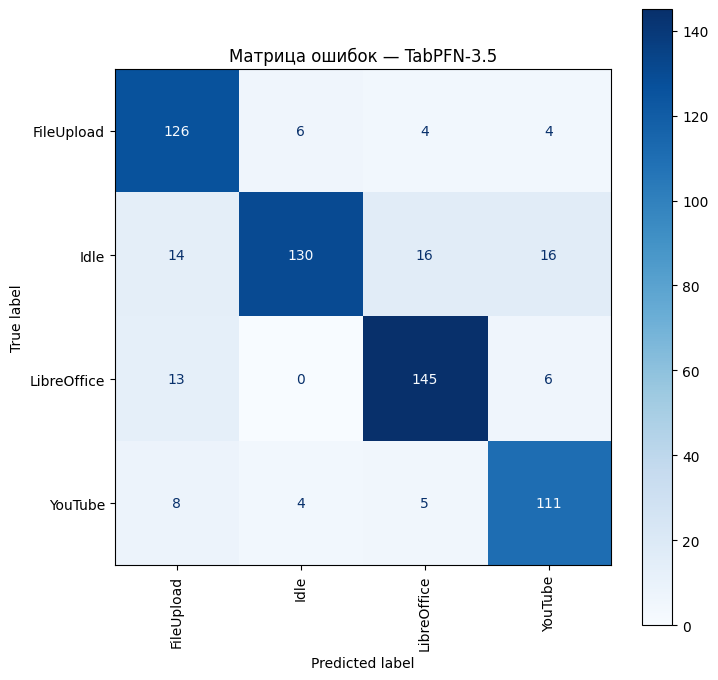

In [20]:
# ЧТО ДЕЛАЕМ: печатаем детальные метрики TabPFN-3.5.
# ЗАЧЕМ: accuracy сама по себе малоинформативна при несбалансированных классах;
# отчёт по классам (classification_report) показывает, какие сценарии модель путает,
# а матрица ошибок — где именно ошибается.

res = RESULTS["TabPFN-3.5"]

print(f"Accuracy: {res['accuracy']:.4f}")
print(classification_report(res["y_test"], res["y_pred"], zero_division=0))

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(res["y_test"], res["y_pred"], ax=ax, xticks_rotation="vertical", cmap="Blues")
ax.set_title("Матрица ошибок — TabPFN-3.5")
plt.show()

## 6. Сравнение с TabPFN-3.5-Fast

TabPFN-3.5-Fast — облегченный вариант для быстрого вывода: ему нужно меньше вычислений,
заявленная точность почти на уровне базовой версии. Прогоним тот же протокол
с теми же данными и тем же разбиением и сведем результаты обеих версий в одну таблицу.

In [18]:
# ЧТО ДЕЛАЕМ: прогоняем TabPFN-3.5-Fast по тому же протоколу и печатаем его детальные метрики.
# ЗАЧЕМ: обе версии работают на одних данных и одном split, поэтому различия цифр
# — это чистый эффект выбора модели, а не предобработки.

RESULTS["TabPFN-3.5-Fast"] = evaluate_tabpfn_variant(ModelVersion.V3_5_FAST, "TabPFN-3.5-Fast")

fast_res = RESULTS["TabPFN-3.5-Fast"]
print(classification_report(fast_res["y_test"], fast_res["y_pred"], zero_division=0))

tabpfn-v3.5-fast-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  334MB            

tabpfn-v3.5-fast-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

[TabPFN-3.5-Fast] fit: 8.0 с | predict: 1.4 с | accuracy: 0.8355
              precision    recall  f1-score   support

  FileUpload       0.76      0.90      0.83       140
        Idle       0.94      0.75      0.83       176
 LibreOffice       0.84      0.89      0.86       164
     YouTube       0.81      0.81      0.81       128

    accuracy                           0.84       608
   macro avg       0.84      0.84      0.83       608
weighted avg       0.84      0.84      0.84       608



In [19]:
# ЧТО ДЕЛАЕМ: сводим результаты обеих версий в одну сводную таблицу.
# ЗАЧЕМ: так наглядно виден компромисс «скорость — точность»: секунды на fit/predict
# и accuracy для TabPFN-3.5 и TabPFN-3.5-Fast на одних данных.

summary = pd.DataFrame(
    [
        {
            "Вариант": r["name"],
            "Accuracy": round(r["accuracy"], 4),
            "fit, с": round(r["fit_seconds"], 1),
            "predict, с": round(r["predict_seconds"], 1),
        }
        for r in RESULTS.values()
    ]
).set_index("Вариант")
print("Сравнение вариантов TabPFN:")
print(summary.to_string())

Сравнение вариантов TabPFN:
                 Accuracy  fit, с  predict, с
Вариант                                      
TabPFN-3.5         0.8421     0.7         3.0
TabPFN-3.5-Fast    0.8355     8.0         1.4


## 7. Выводы

**Ответ 1: обязательна ли GPU или можно на CPU?**

GPU **не обязателен**. TabPFN-3.5 — трансформер ~220 млн параметров; официальный README допускает CPU
для умеренных датасетов (лимит ~5000 строк для TabPFN-3 / 3.5 / 3.5-Fast), а наш датасет — фрагменты
по 90 точек мощности, обычно несколько тысяч строк. Фактические тайминги fit/predict — в ячейках
разделов 5 и 6; на CPU это будет заметно дольше, но задача решается. На GPU рекомендация ~8 ГБ VRAM
запасом покрывает эту задачу, и лимит строк снимается.

**Ответ 2: поместится ли в T4 из бесплатного Colab?**

Да, с большим запасом. T4 — это 16 ГБ VRAM; весовой файл TabPFN-3.5 — ~0,9 ГБ, а 16 ГБ упоминаются
документацией только как запас для очень больших контекстов. Фактическое окружение печатается в разделе 3.

**Практические рекомендации:**

- если есть возможность, запускайте на T4: предсказания почти мгновенные и работает полный объем выборки;
- если важнее скорость загрузки и вывод — пробуйте **TabPFN-3.5-Fast**: у него меньше задержки почти при той же точности (сравнение — в таблице раздела 6);
- помните о лицензии: веса TabPFN-3.5 некоммерческие (тестирование и внутренняя оценка разрешены, продакшен — нет).

**Возможный следующий шаг:** сравнить результат с конвейером TimesFM3 + RandomForest из референс-ноутбука
на тех же данных и том же разбиении.